> # SUPERSEDED
>
> This notebook is out-of-distribution and noise sweeps on `data/raw/llm_generated`.
>
> **That benchmark has been withdrawn.** A logistic regression given a single record's 384-dimensional embedding -- no graph, no edges, no temporal order -- scores **AUROC 1.0000** on it. The label was recoverable from one record's text, so no graph model was being tested. On the replacement benchmark `ap_burst2k` the same probe scores 0.5300.
>
> These sweeps have **not** been re-measured on `ap_burst2k`. The qualitative finding that embedding quality is the sole critical input is confounded: it was measured on a dataset whose entire signal is content, which is exactly the condition under which embedding sensitivity would be maximal. Treat it as open.
>
> The notebook is kept as the record of what was originally run. **Do not quote its numbers as current results.**
>
> Current results: `notebooks/ap_burst2k_reproduction.ipynb` -- sequence-level AUROC 0.8122, AP 0.8185.


# 06: Out-of-Distribution (OOD) Noise & Stress-Testing

This notebook evaluates the trained Temporal Graph Neural Network (TGN) memory poisoning detector under algorithmic noise perturbations and Out-of-Distribution (OOD) stress tests:
1. **Gaussian Embedding Noise ($\sigma$ Sweep):** Simulates semantic feature drift from noisy LLM outputs or embedding model changes.
2. **Topological Threshold Sensitivity ($	heta$ Sweep):** Evaluates multi-head GAT attention under varying edge density thresholds ($	heta \in [0.4, 0.8]$).
3. **Metadata Jitter & Corruption:** Evaluates robustness under operational log missingness and timestamp noise.
4. **Random Edge Loss:** Tests resilience against sparse or incomplete memory indexing.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

EXP_DIR = Path('../experiments')
IMG_DIR = EXP_DIR / 'eval_images'
IMG_DIR.mkdir(parents=True, exist_ok=True)

print('Environment initialized successfully.')

Environment initialized successfully.


## 1. Load OOD Evaluation Results

In [2]:
results_file = EXP_DIR / 'ood_results.json'
with open(results_file) as f:
    results = json.load(f)

print('Clean Baseline Results:')
for k, v in results['baseline_clean'].items():
    print(f'  {k:20s}: {v}')

Clean Baseline Results:
  graph_auroc         : 1.0
  graph_ap            : 1.0
  graph_f1            : 0.9822
  fpr_at_tpr90        : 0.0
  node_auroc          : 0.9737
  node_ap             : 0.634


## 2. Gaussian Embedding Noise Decay ($\sigma$ Sweep)

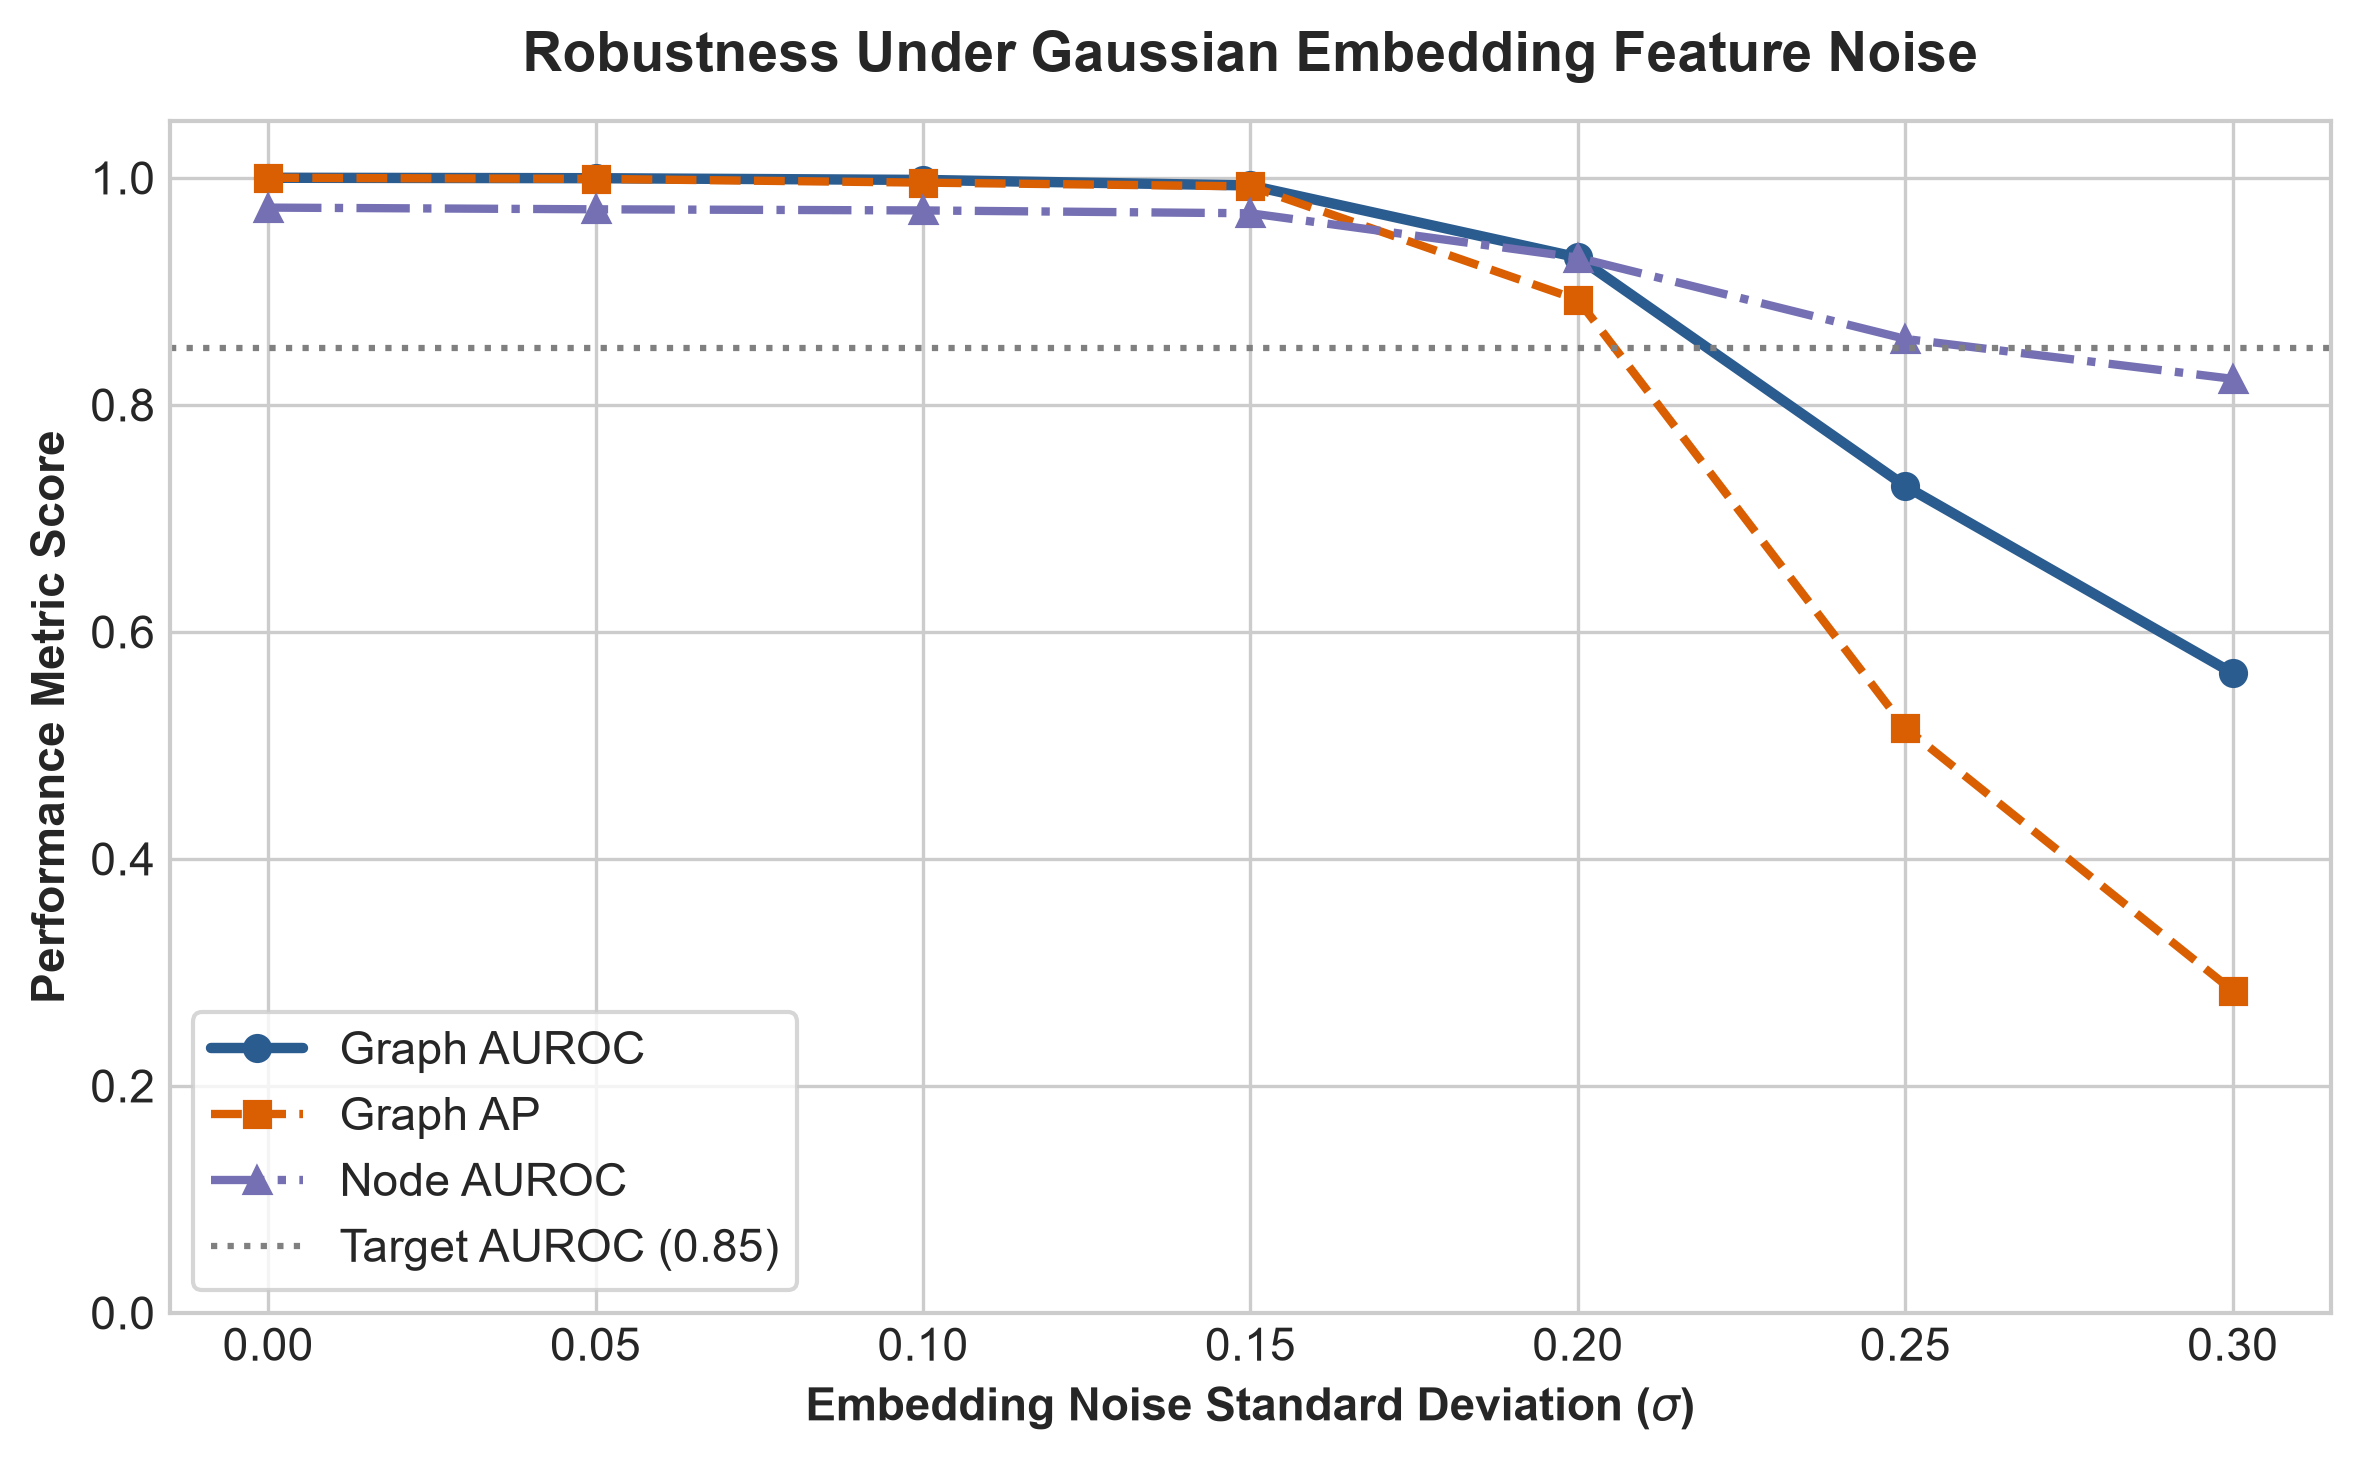

,graph_auroc,graph_ap,graph_f1,fpr_at_tpr90,node_auroc,node_ap
sigma,,,,,,
0.0,1.0000,1.0000,0.9822,0.0000,0.9737,0.6333
0.05,0.9996,0.9990,0.9762,0.0000,0.9722,0.6239
0.1,0.9981,0.9957,0.9822,0.0000,0.9712,0.6125
0.15,0.9932,0.9924,0.9497,0.0000,0.9687,0.5448
0.2,0.9298,0.8925,0.4311,0.1270,0.9296,0.4155
0.25,0.7283,0.5152,0.4135,0.4385,0.8580,0.3197
0.3,0.5635,0.2837,0.4135,0.6885,0.8228,0.2596


In [3]:
noise_data = results['embedding_noise_sweep']
sigmas = [float(k) for k in noise_data.keys()]
g_auroc = [v['graph_auroc'] for v in noise_data.values()]
g_ap = [v['graph_ap'] for v in noise_data.values()]
n_auroc = [v['node_auroc'] for v in noise_data.values()]

fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
ax.plot(sigmas, g_auroc, 'o-', color='#2b5c8f', linewidth=2.5, label='Graph AUROC')
ax.plot(sigmas, g_ap, 's--', color='#d95f02', linewidth=2.0, label='Graph AP')
ax.plot(sigmas, n_auroc, '^-.', color='#7570b3', linewidth=2.0, label='Node AUROC')

ax.axhline(0.85, color='gray', linestyle=':', label='Target AUROC (0.85)')
ax.set_xlabel(r'Embedding Noise Standard Deviation ($\sigma$)', fontweight='bold')
ax.set_ylabel('Performance Metric Score', fontweight='bold')
ax.set_title('Robustness Under Gaussian Embedding Feature Noise', fontweight='bold', pad=12)
ax.set_ylim(0.0, 1.05)
ax.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.savefig(IMG_DIR / 'ood_embedding_noise_decay.png', dpi=300)
plt.show()

df_noise = pd.DataFrame(noise_data).T
df_noise.index.name = 'sigma'
display(df_noise)

## 3. Dynamic Cosine Threshold Sensitivity ($	heta$ Sweep)

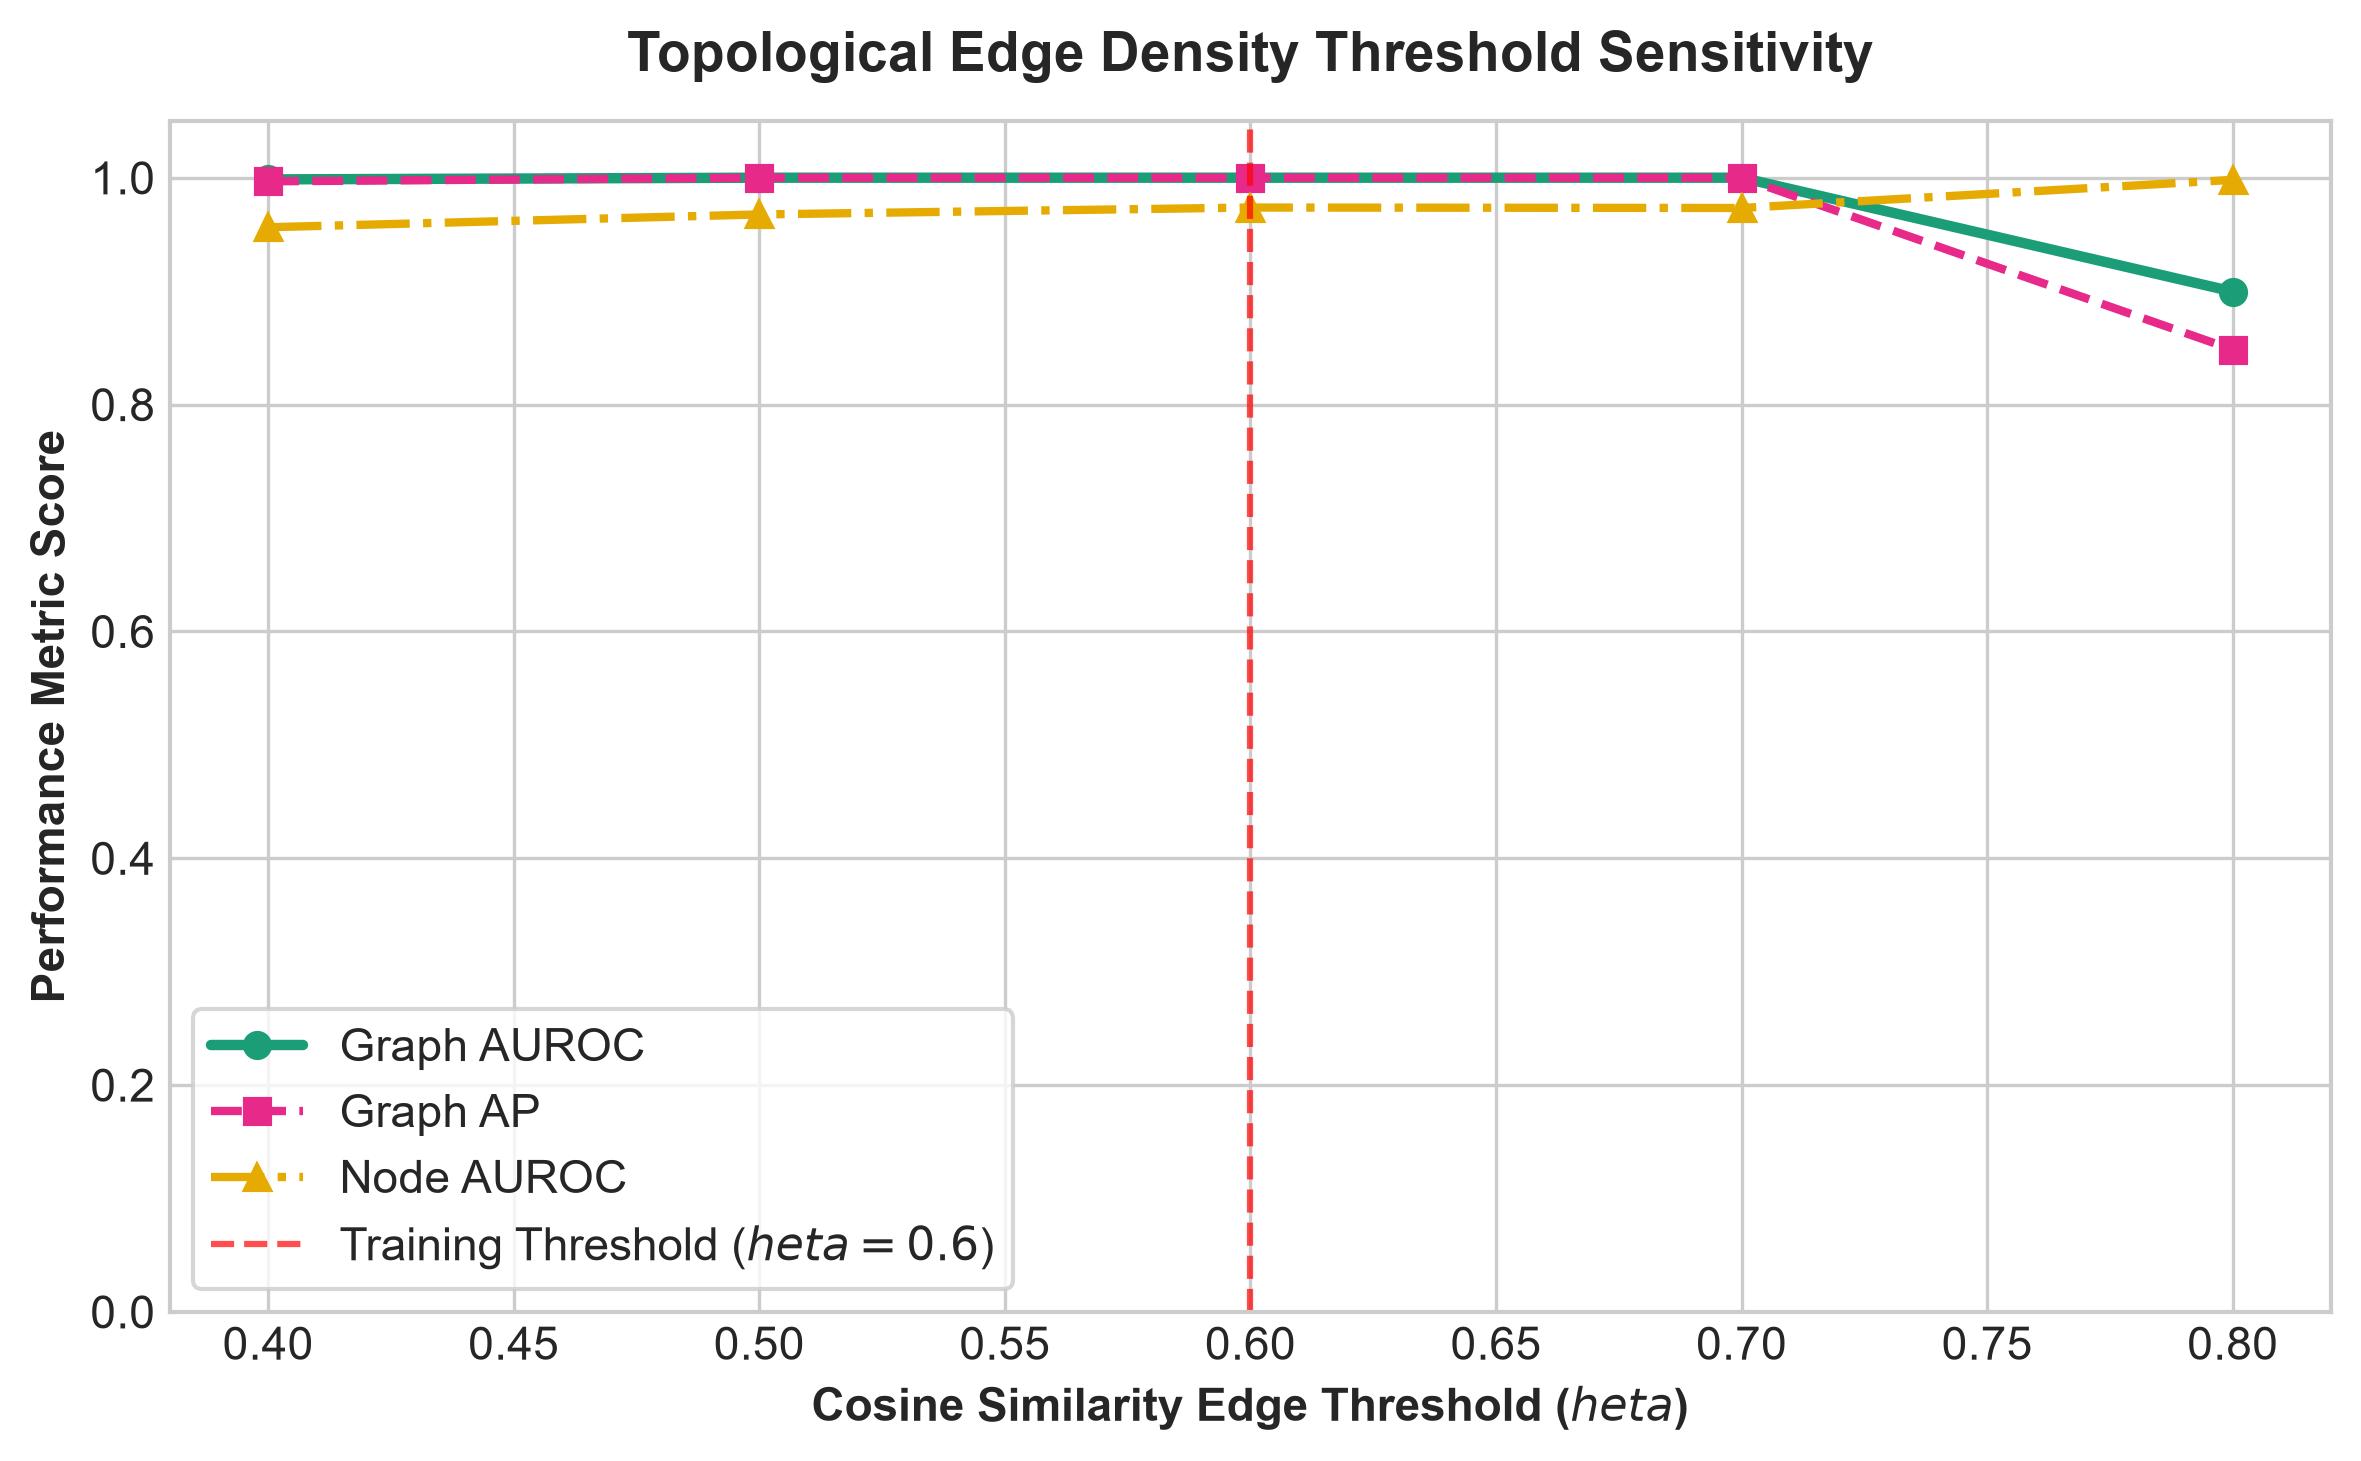

,graph_auroc,graph_ap,graph_f1,fpr_at_tpr90,node_auroc,node_ap
theta,,,,,,
0.4,0.9985,0.9968,0.9576,0.0000,0.9563,0.3127
0.5,1.0000,1.0000,0.9701,0.0000,0.9676,0.5090
0.6,1.0000,1.0000,0.9822,0.0000,0.9737,0.6339
0.7,1.0000,1.0000,0.9383,0.0000,0.9733,0.6497
0.8,0.8996,0.8484,0.6870,0.4467,0.9981,0.9070


In [4]:
thresh_data = results['threshold_sensitivity_sweep']
thetas = [float(k) for k in thresh_data.keys()]
g_auroc_t = [v['graph_auroc'] for v in thresh_data.values()]
g_ap_t = [v['graph_ap'] for v in thresh_data.values()]
n_auroc_t = [v['node_auroc'] for v in thresh_data.values()]

fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
ax.plot(thetas, g_auroc_t, 'o-', color='#1b9e77', linewidth=2.5, label='Graph AUROC')
ax.plot(thetas, g_ap_t, 's--', color='#e7298a', linewidth=2.0, label='Graph AP')
ax.plot(thetas, n_auroc_t, '^-.', color='#e6ab02', linewidth=2.0, label='Node AUROC')

ax.axvline(0.6, color='red', linestyle='--', alpha=0.7, label=r'Training Threshold ($	heta=0.6$)')
ax.set_xlabel(r'Cosine Similarity Edge Threshold ($	heta$)', fontweight='bold')
ax.set_ylabel('Performance Metric Score', fontweight='bold')
ax.set_title('Topological Edge Density Threshold Sensitivity', fontweight='bold', pad=12)
ax.set_ylim(0.0, 1.05)
ax.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.savefig(IMG_DIR / 'ood_threshold_sensitivity.png', dpi=300)
plt.show()

df_thresh = pd.DataFrame(thresh_data).T
df_thresh.index.name = 'theta'
display(df_thresh)

## 4. Operational Metadata Corruption & Edge Loss

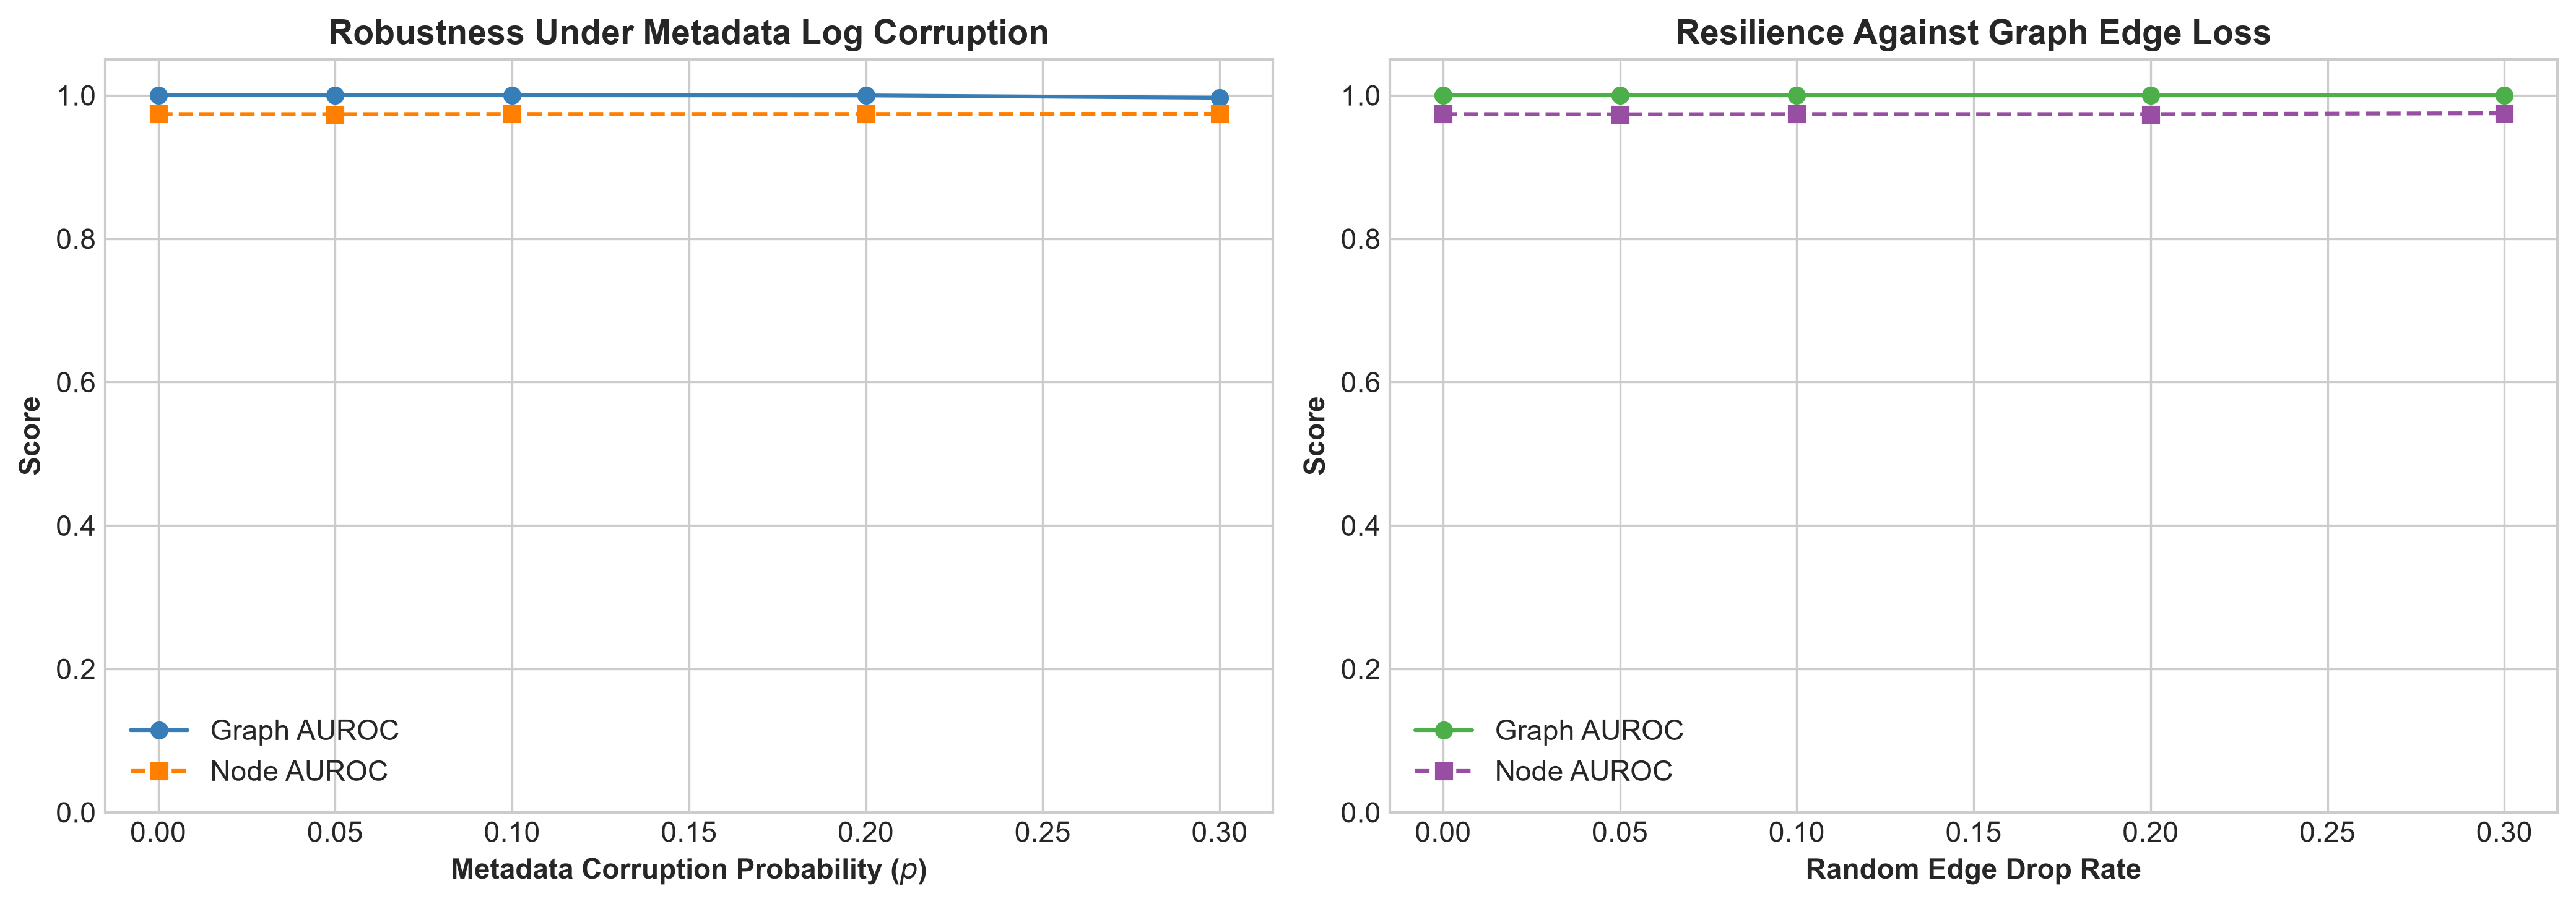

In [5]:
meta_data = results['metadata_corruption_sweep']
edge_data = results['edge_loss_sweep']

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

# Subplot 1: Metadata Corruption
m_p = [float(k) for k in meta_data.keys()]
axes[0].plot(m_p, [v['graph_auroc'] for v in meta_data.values()], 'o-', color='#377eb8', label='Graph AUROC')
axes[0].plot(m_p, [v['node_auroc'] for v in meta_data.values()], 's--', color='#ff7f00', label='Node AUROC')
axes[0].set_xlabel('Metadata Corruption Probability ($p$)', fontweight='bold')
axes[0].set_ylabel('Score', fontweight='bold')
axes[0].set_title('Robustness Under Metadata Log Corruption', fontweight='bold')
axes[0].set_ylim(0.0, 1.05)
axes[0].legend()

# Subplot 2: Random Edge Drop Rate
e_r = [float(k) for k in edge_data.keys()]
axes[1].plot(e_r, [v['graph_auroc'] for v in edge_data.values()], 'o-', color='#4daf4a', label='Graph AUROC')
axes[1].plot(e_r, [v['node_auroc'] for v in edge_data.values()], 's--', color='#984ea3', label='Node AUROC')
axes[1].set_xlabel('Random Edge Drop Rate', fontweight='bold')
axes[1].set_ylabel('Score', fontweight='bold')
axes[1].set_title('Resilience Against Graph Edge Loss', fontweight='bold')
axes[1].set_ylim(0.0, 1.05)
axes[1].legend()

plt.tight_layout()
plt.savefig(IMG_DIR / 'ood_metadata_and_edge_loss.png', dpi=300)
plt.show()

## 5. Summary Dashboard (Publication & Thesis Artifact)

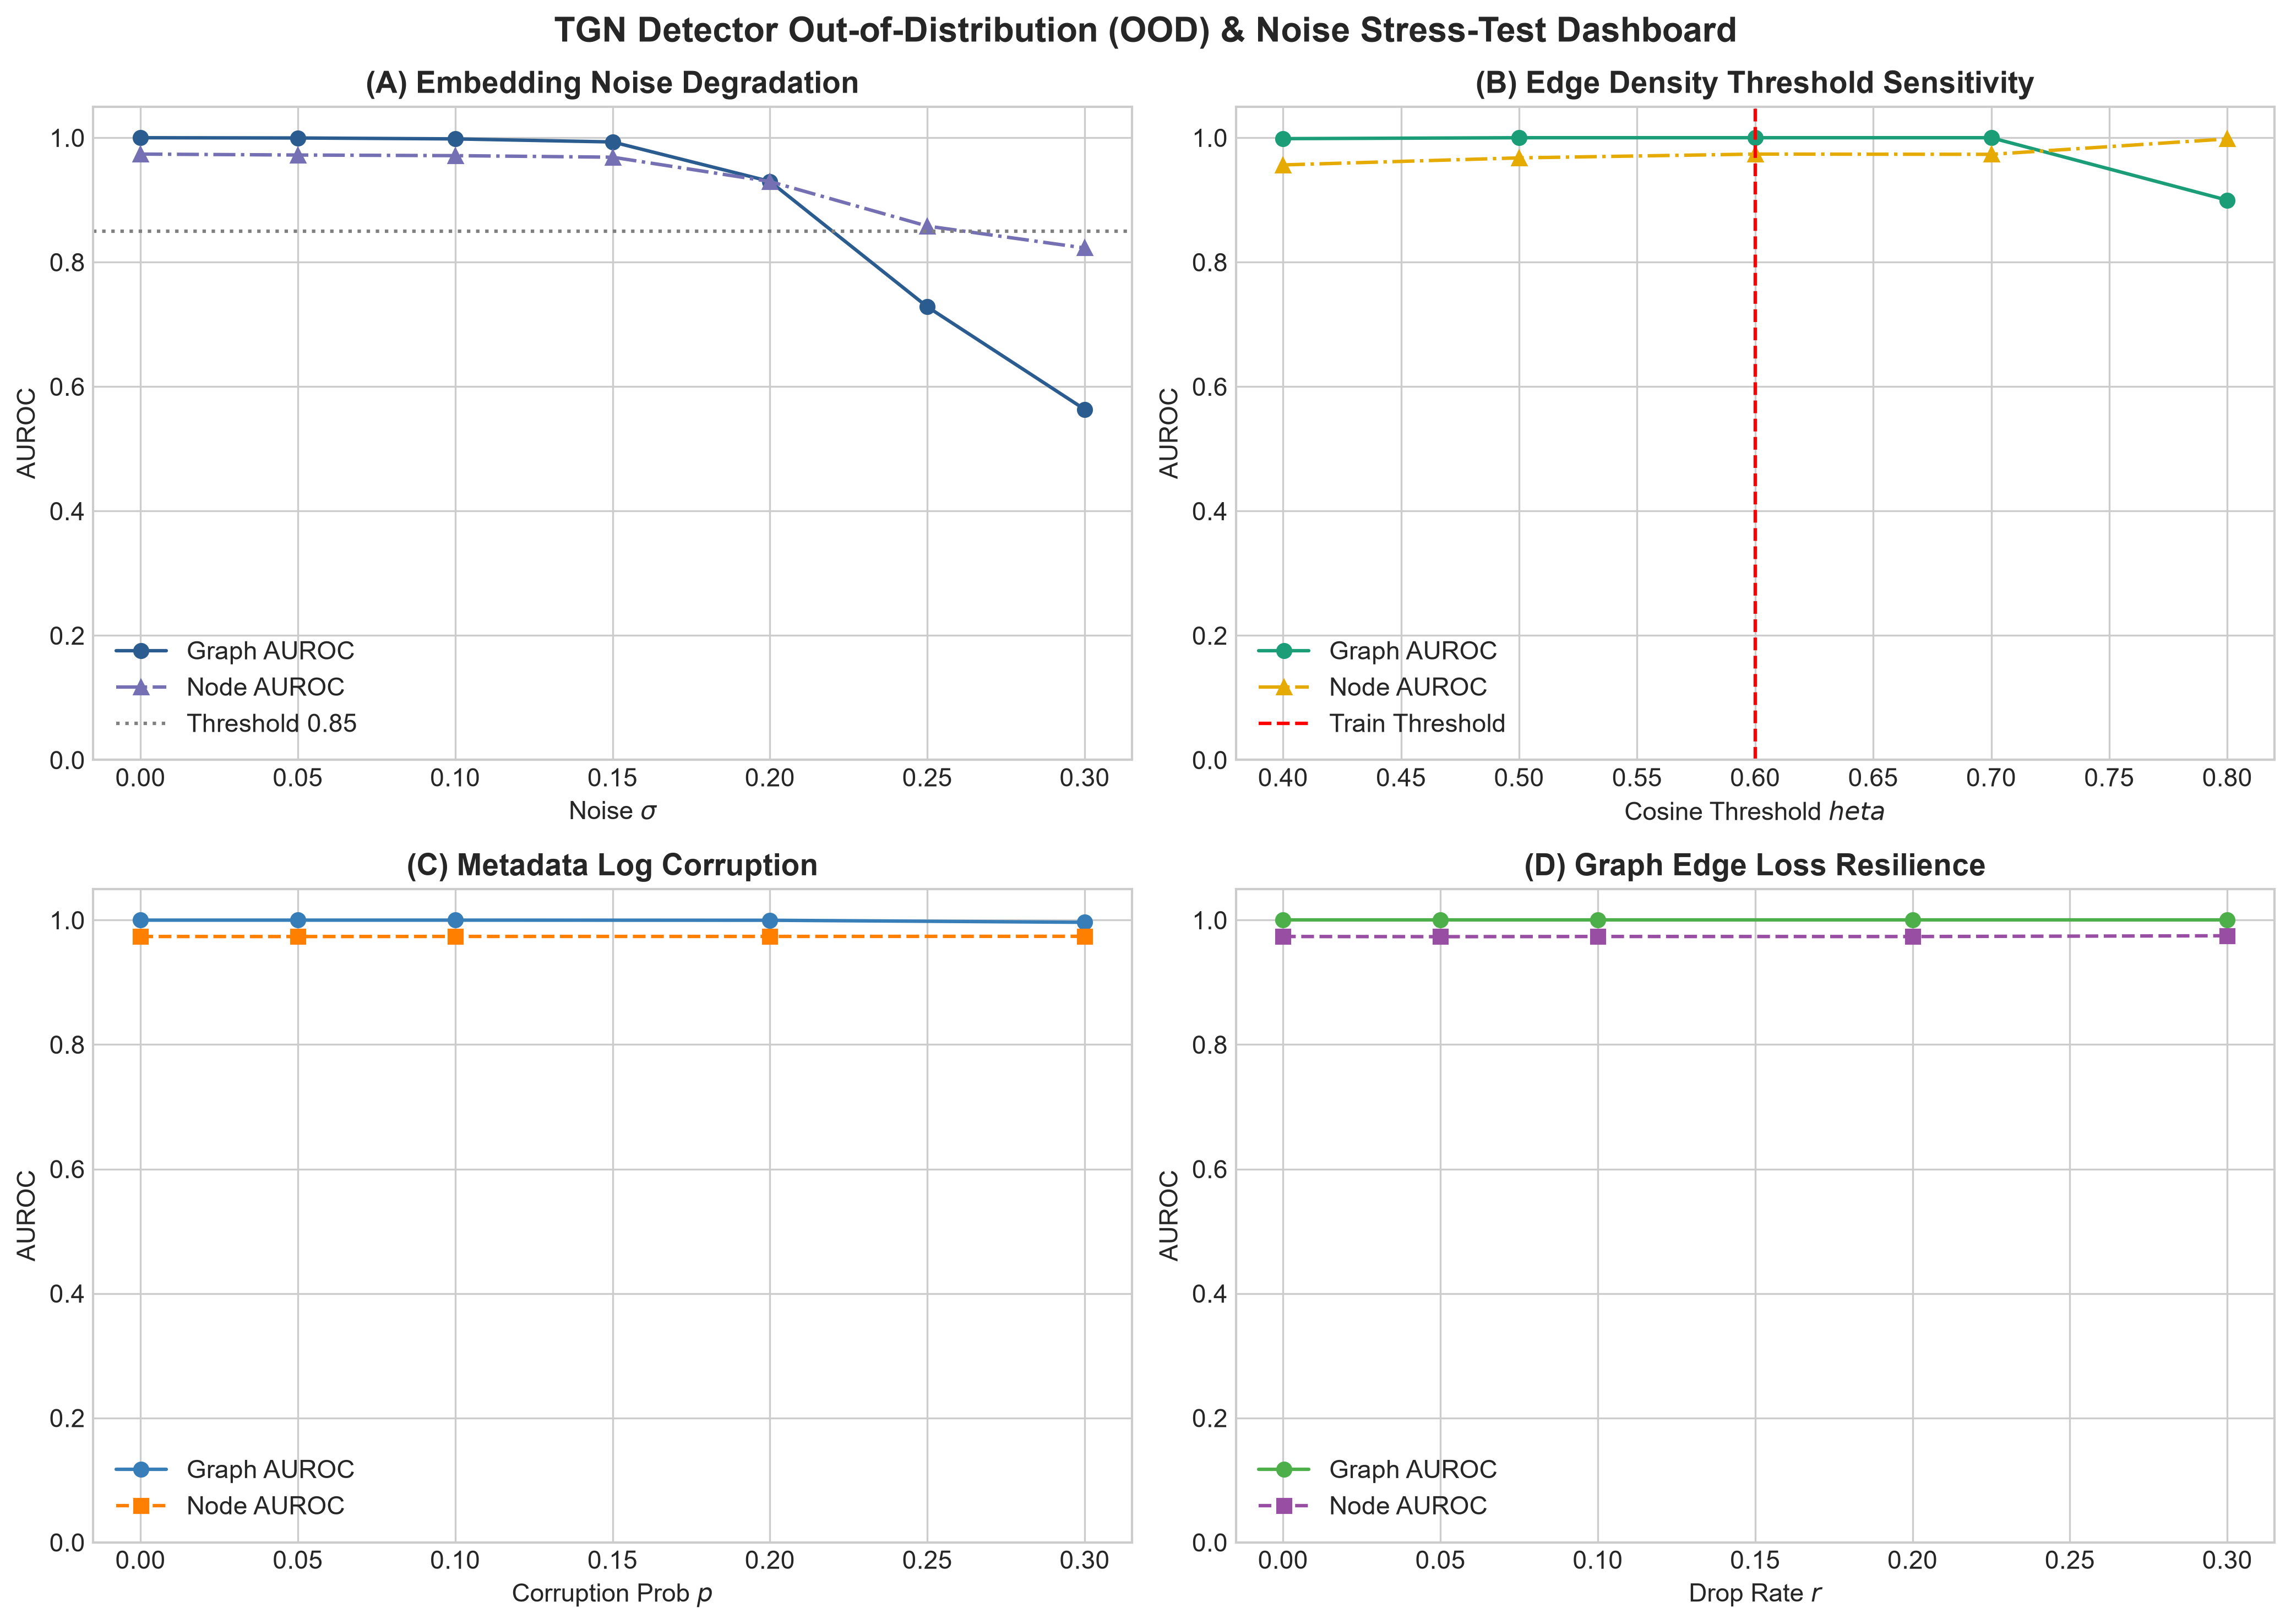

Dashboard exported to experiments/eval_images/ood_summary_dashboard.png


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=300)

# Panel A: Embedding Noise
axes[0, 0].plot(sigmas, g_auroc, 'o-', color='#2b5c8f', label='Graph AUROC')
axes[0, 0].plot(sigmas, n_auroc, '^-.', color='#7570b3', label='Node AUROC')
axes[0, 0].axhline(0.85, color='gray', linestyle=':', label='Threshold 0.85')
axes[0, 0].set_title('(A) Embedding Noise Degradation', fontweight='bold')
axes[0, 0].set_xlabel(r'Noise $\sigma$')
axes[0, 0].set_ylabel('AUROC')
axes[0, 0].set_ylim(0.0, 1.05)
axes[0, 0].legend()

# Panel B: Cosine Threshold
axes[0, 1].plot(thetas, g_auroc_t, 'o-', color='#1b9e77', label='Graph AUROC')
axes[0, 1].plot(thetas, n_auroc_t, '^-.', color='#e6ab02', label='Node AUROC')
axes[0, 1].axvline(0.6, color='red', linestyle='--', label='Train Threshold')
axes[0, 1].set_title('(B) Edge Density Threshold Sensitivity', fontweight='bold')
axes[0, 1].set_xlabel(r'Cosine Threshold $	heta$')
axes[0, 1].set_ylabel('AUROC')
axes[0, 1].set_ylim(0.0, 1.05)
axes[0, 1].legend()

# Panel C: Metadata Jitter
axes[1, 0].plot(m_p, [v['graph_auroc'] for v in meta_data.values()], 'o-', color='#377eb8', label='Graph AUROC')
axes[1, 0].plot(m_p, [v['node_auroc'] for v in meta_data.values()], 's--', color='#ff7f00', label='Node AUROC')
axes[1, 0].set_title('(C) Metadata Log Corruption', fontweight='bold')
axes[1, 0].set_xlabel('Corruption Prob $p$')
axes[1, 0].set_ylabel('AUROC')
axes[1, 0].set_ylim(0.0, 1.05)
axes[1, 0].legend()

# Panel D: Edge Loss
axes[1, 1].plot(e_r, [v['graph_auroc'] for v in edge_data.values()], 'o-', color='#4daf4a', label='Graph AUROC')
axes[1, 1].plot(e_r, [v['node_auroc'] for v in edge_data.values()], 's--', color='#984ea3', label='Node AUROC')
axes[1, 1].set_title('(D) Graph Edge Loss Resilience', fontweight='bold')
axes[1, 1].set_xlabel('Drop Rate $r$')
axes[1, 1].set_ylabel('AUROC')
axes[1, 1].set_ylim(0.0, 1.05)
axes[1, 1].legend()

plt.suptitle('TGN Detector Out-of-Distribution (OOD) & Noise Stress-Test Dashboard', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig(IMG_DIR / 'ood_summary_dashboard.png', dpi=300)
plt.show()
print('Dashboard exported to experiments/eval_images/ood_summary_dashboard.png')